In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


Messung A1.1


In [10]:
R_e = 3.0e3
dR_e = 0.10 * R_e

# DC
U1_dc = np.array([250, 200, 150, 100, 50, 0, -50, -100, -150, -200, -250]) * 1e-3
dU1_dc = 1.0e-3

Ua_dc_487 = np.array([-3.89, -3.10, -2.31, -1.40, -0.60, 0.20, 1.00, 2.00, 2.67, 3.41, 4.30])
Ua_dc_274 = np.array([-12.80, -12.80, -12.70, -9.20, -4.74, -0.12, 4.42, 8.81, 13.80, 14.60, 14.70])
dUa_dc = 0.10

# AC (1 kHz)
Uss_ac = np.array([50, 200, 350, 500, 650, 800, 1000]) * 1e-3

UG_ac_274 = np.array([14, 58, 103, 146, 190, 235, 293]) * 1e-3
U1_ac_274 = UG_ac_274 / 10
Ua_ac_274 = np.array([130, 531, 921, 1320, 1710, 2110, 2620]) * 1e-3

UG_ac_680 = np.array([14, 59, 103, 146, 191, 235, 293]) * 1e-3
U1_ac_680 = UG_ac_680 / 10
Ua_ac_680 = np.array([321, 1290, 2250, 3180, 4130, 5090, 6370]) * 1e-3

dUG_ac = 3.0e-3
dU1_ac = dUG_ac / 10
dUa_ac = 10.0e-3


A1 berechenen

In [11]:
def lin_model(x, m, b):
    return m * x + b

def fit_linear(x, y, dx, dy):
    popt, pcov = curve_fit(lin_model, x, y, sigma=np.full_like(y, dy), absolute_sigma=True)
    for _ in range(3):
        dy_eff = np.sqrt(dy**2 + (popt[0] * dx)**2)
        popt, pcov = curve_fit(lin_model, x, y, sigma=dy_eff, absolute_sigma=True)
    perr = np.sqrt(np.diag(pcov))
    return popt, perr

popt_dc487, perr_dc487 = fit_linear(U1_dc, Ua_dc_487, dU1_dc, dUa_dc)

lin_mask_274 = np.zeros(len(U1_dc), dtype=bool)
lin_mask_274[3:9] = True
popt_dc274, perr_dc274 = fit_linear(U1_dc[lin_mask_274], Ua_dc_274[lin_mask_274], dU1_dc, dUa_dc)

popt_ac274, perr_ac274 = fit_linear(U1_ac_274, Ua_ac_274, dU1_ac, dUa_ac)
popt_ac680, perr_ac680 = fit_linear(U1_ac_680, Ua_ac_680, dU1_ac, dUa_ac)

for label, Rg, V_m, dV_m, b, db in [
    ('DC 48.7k', 48.7e3, -popt_dc487[0], perr_dc487[0], popt_dc487[1], perr_dc487[1]),
    ('DC 274k ', 274.0e3, -popt_dc274[0], perr_dc274[0], popt_dc274[1], perr_dc274[1]),
    ('AC 274k ', 274.0e3,  popt_ac274[0], perr_ac274[0], popt_ac274[1], perr_ac274[1]),
    ('AC 680k ', 680.0e3,  popt_ac680[0], perr_ac680[0], popt_ac680[1], perr_ac680[1]),
]:
    V_th = Rg / R_e
    dV_th = V_th * np.sqrt(0.10**2 + 0.10**2)
    z = abs(V_m - V_th) / np.sqrt(dV_m**2 + dV_th**2)
    print(f'{label}: V = {V_m:.2f} +- {dV_m:.2f}, U_off = {b:.3f} +- {db:.3f}, V_th = {V_th:.2f} +- {dV_th:.2f}, z = {z:.2f}')


DC 48.7k: V = 16.42 +- 0.19, U_off = 0.207 +- 0.031, V_th = 16.23 +- 2.30, z = 0.08
DC 274k : V = 91.54 +- 0.65, U_off = -0.127 +- 0.058, V_th = 91.33 +- 12.92, z = 0.02
AC 274k : V = 89.32 +- 1.18, U_off = 0.009 +- 0.021, V_th = 91.33 +- 12.92, z = 0.16
AC 680k : V = 216.38 +- 2.72, U_off = 0.015 +- 0.047, V_th = 226.67 +- 32.06, z = 0.32


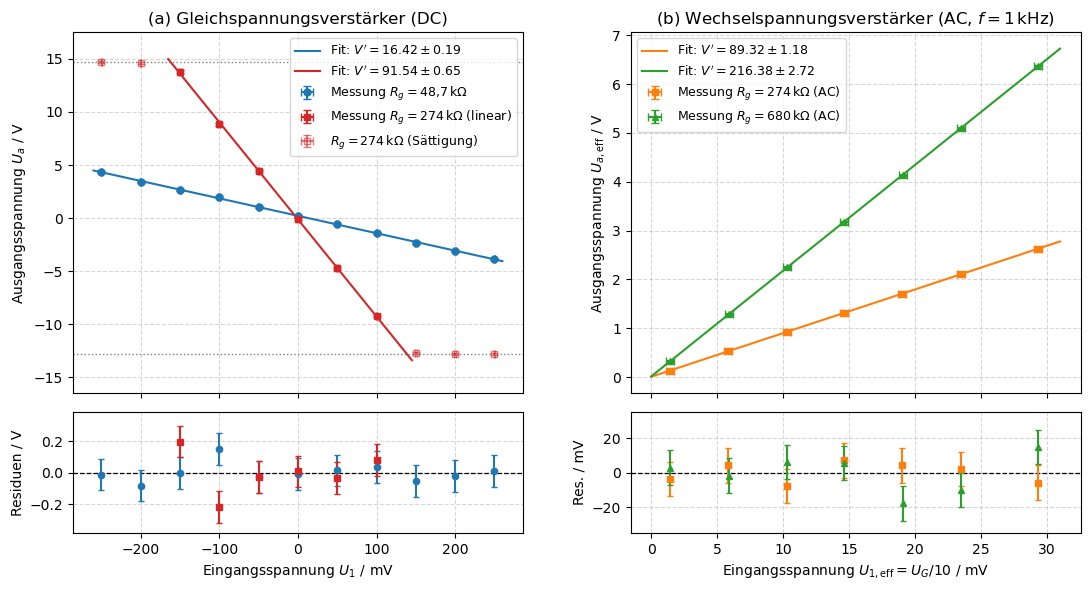

In [ ]:
fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1], hspace=0.08, wspace=0.24)

ax_dc = fig.add_subplot(gs[0, 0])
ax_dc_res = fig.add_subplot(gs[1, 0], sharex=ax_dc)
ax_ac = fig.add_subplot(gs[0, 1])
ax_ac_res = fig.add_subplot(gs[1, 1], sharex=ax_ac)

x_dc = np.linspace(-260, 260, 200)
ax_dc.errorbar(U1_dc * 1e3, Ua_dc_487, xerr=dU1_dc * 1e3, yerr=dUa_dc,
               fmt='o', color='#1f77b4', capsize=3, markersize=5,
               label=r'Messung $R_g = 48{,}7\,\mathrm{k\Omega}$')
ax_dc.plot(x_dc, lin_model(x_dc * 1e-3, *popt_dc487), '-', color='#1f77b4',
           label=rf'Fit: $V^\prime = {-popt_dc487[0]:.2f} \pm {perr_dc487[0]:.2f}$')

ax_dc.errorbar(U1_dc[lin_mask_274] * 1e3, Ua_dc_274[lin_mask_274],
               xerr=dU1_dc * 1e3, yerr=dUa_dc,
               fmt='s', color='#d62728', capsize=3, markersize=5,
               label=r'Messung $R_g = 274\,\mathrm{k\Omega}$ (linear)')
ax_dc.errorbar(U1_dc[~lin_mask_274] * 1e3, Ua_dc_274[~lin_mask_274],
               xerr=dU1_dc * 1e3, yerr=dUa_dc,
               fmt='s', color='#d62728', mfc='none', capsize=3, markersize=5, alpha=0.6,
               label=r'$R_g = 274\,\mathrm{k\Omega}$ (Sättigung)')
x_dc_274 = np.linspace(-165, 145, 200)
ax_dc.plot(x_dc_274, lin_model(x_dc_274 * 1e-3, *popt_dc274), '-', color='#d62728',
           label=rf'Fit: $V^\prime = {-popt_dc274[0]:.2f} \pm {perr_dc274[0]:.2f}$')

ax_dc.axhline(14.65, color='gray', ls=':', lw=1)
ax_dc.axhline(-12.77, color='gray', ls=':', lw=1)
ax_dc.set_ylabel(r'Ausgangsspannung $U_a\ /\ \mathrm{V}$')
ax_dc.set_title('(a) Gleichspannungsverstärker (DC)')
ax_dc.grid(True, ls='--', alpha=0.5)
ax_dc.legend(loc='upper right', fontsize=9)
ax_dc.set_ylim(-16.5, 17.5)
plt.setp(ax_dc.get_xticklabels(), visible=False)

res_dc487 = Ua_dc_487 - lin_model(U1_dc, *popt_dc487)
res_dc274 = Ua_dc_274[lin_mask_274] - lin_model(U1_dc[lin_mask_274], *popt_dc274)
ax_dc_res.axhline(0, color='black', lw=0.9, ls='--')
ax_dc_res.errorbar(U1_dc * 1e3, res_dc487, yerr=dUa_dc, fmt='o', color='#1f77b4', capsize=2.5, markersize=4.5)
ax_dc_res.errorbar(U1_dc[lin_mask_274] * 1e3, res_dc274, yerr=dUa_dc, fmt='s', color='#d62728', capsize=2.5, markersize=4.5)
ax_dc_res.set_xlabel(r'Eingangsspannung $U_1\ /\ \mathrm{mV}$')
ax_dc_res.set_ylabel('Residuen / V')
ax_dc_res.grid(True, ls='--', alpha=0.5)
ax_dc_res.set_ylim(-0.38, 0.38)

x_ac = np.linspace(0, 31, 200)
ax_ac.errorbar(U1_ac_274 * 1e3, Ua_ac_274, xerr=dU1_ac * 1e3, yerr=dUa_ac,
               fmt='s', color='#ff7f0e', capsize=3, markersize=5,
               label=r'Messung $R_g = 274\,\mathrm{k\Omega}$ (AC)')
ax_ac.plot(x_ac, lin_model(x_ac * 1e-3, *popt_ac274), '-', color='#ff7f0e',
           label=rf'Fit: $V^\prime = {popt_ac274[0]:.2f} \pm {perr_ac274[0]:.2f}$')

ax_ac.errorbar(U1_ac_680 * 1e3, Ua_ac_680, xerr=dU1_ac * 1e3, yerr=dUa_ac,
               fmt='^', color='#2ca02c', capsize=3, markersize=5,
               label=r'Messung $R_g = 680\,\mathrm{k\Omega}$ (AC)')
ax_ac.plot(x_ac, lin_model(x_ac * 1e-3, *popt_ac680), '-', color='#2ca02c',
           label=rf'Fit: $V^\prime = {popt_ac680[0]:.2f} \pm {perr_ac680[0]:.2f}$')

ax_ac.set_ylabel(r'Ausgangsspannung $U_{a,\mathrm{eff}}\ /\ \mathrm{V}$')
ax_ac.set_title(r'(b) Wechselspannungsverstärker (AC, $f = 1\,\mathrm{kHz}$)')
ax_ac.grid(True, ls='--', alpha=0.5)
ax_ac.legend(loc='upper left', fontsize=9)
plt.setp(ax_ac.get_xticklabels(), visible=False)

res_ac274 = (Ua_ac_274 - lin_model(U1_ac_274, *popt_ac274)) * 1e3
res_ac680 = (Ua_ac_680 - lin_model(U1_ac_680, *popt_ac680)) * 1e3
ax_ac_res.axhline(0, color='black', lw=0.9, ls='--')
ax_ac_res.errorbar(U1_ac_274 * 1e3, res_ac274, yerr=dUa_ac * 1e3, fmt='s', color='#ff7f0e', capsize=2.5, markersize=4.5)
ax_ac_res.errorbar(U1_ac_680 * 1e3, res_ac680, yerr=dUa_ac * 1e3, fmt='^', color='#2ca02c', capsize=2.5, markersize=4.5)
ax_ac_res.set_xlabel(r'Eingangsspannung $U_{1,\mathrm{eff}} = U_G/10\ /\ \mathrm{mV}$')
ax_ac_res.set_ylabel('Res. / mV')
ax_ac_res.grid(True, ls='--', alpha=0.5)
ax_ac_res.set_ylim(-35, 35)



In [13]:
f1 = np.array([100, 300, 600, 1000, 3000, 6000, 10000, 30000, 60000, 100e3, 200e3, 300e3])


In [14]:
# 0.3VPP
Ueff_680 = np.array([2.03, 2.02, 1.99, 1.92, 1.42, 1.03, 0.57, 0.20, 0.11, 0.06, 0.03, 0.02])
delta_Ueff_680 = 0.010

Ueff_274 = np.array([791, 793, 790, 786, 734, 616, 477, 196, 103, 67, 42, 35])*1e-3
delta_Ueff274 = 3e-3

# 1Vpp
Ueff_487 = np.array([469, 470, 470, 470, 467, 463, 454, 378, 255, 178, 97, 66])*1e-3
delta_487 = 3e-3

# 1Vpp, C=560pF
Ueff_487_560 = np.array([466, 466, 465, 460, 418, 331, 243, 92, 48, 29, 16, 11])*1e-3
delta_487_560 = 3e-3


In [15]:
f2 = np.array([300, 600, 900, 3000, 6000, 9000, 10000, 15000, 20000])

# Hochpass (C = 47 nF) mit Gegenkopplung Rg = 48.7 kOhm, C = 560 pF (1Vpp)
Ueff_487_560_47 = np.array([135, 236, 304, 394, 324, 256, 237, 172, 134]) * 1e-3
delta_487_560_47 = 3e-3

Us = [Ueff_680, Ueff_274, Ueff_487, Ueff_487_560, Ueff_487_560_47]
delta_Us = [delta_Ueff_680, delta_Ueff274, delta_487, delta_487_560, delta_487_560_47]


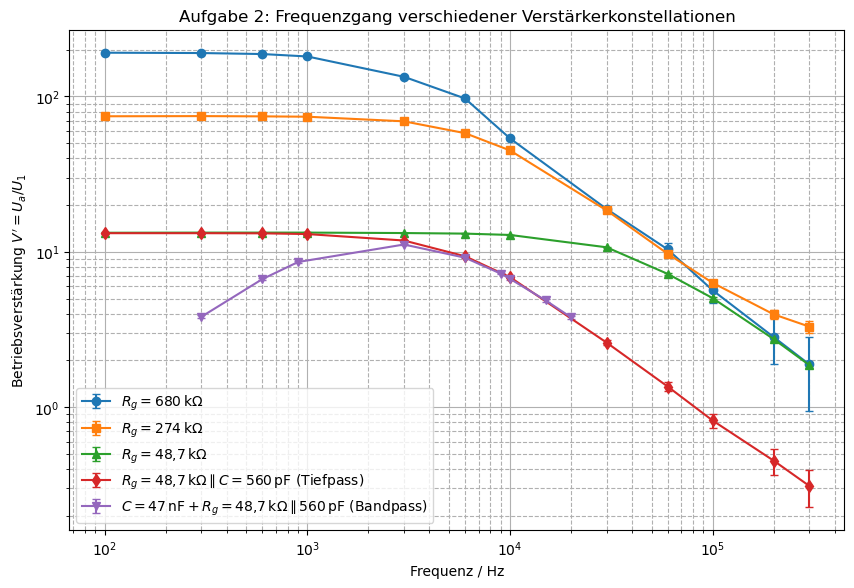

In [ ]:
def calc_V(U_eff, dU_eff, U_g):
    faktor = 20 * np.sqrt(2) / U_g
    return U_eff * faktor, dU_eff * faktor

V_680, dV_680 = calc_V(Ueff_680, delta_Ueff_680, 0.3)
V_274, dV_274 = calc_V(Ueff_274, delta_Ueff274, 0.3)
V_487, dV_487 = calc_V(Ueff_487, delta_487, 1.0)
V_tp, dV_tp = calc_V(Ueff_487_560, delta_487_560, 1.0)
V_bp, dV_bp = calc_V(Ueff_487_560_47, delta_487_560_47, 1.0)

plt.figure(figsize=(10, 6.5))
plt.errorbar(f1, V_680, yerr=dV_680, fmt='-o', capsize=3, label=r'$R_g = 680\,\mathrm{k\Omega}$')
plt.errorbar(f1, V_274, yerr=dV_274, fmt='-s', capsize=3, label=r'$R_g = 274\,\mathrm{k\Omega}$')
plt.errorbar(f1, V_487, yerr=dV_487, fmt='-^', capsize=3, label=r'$R_g = 48{,}7\,\mathrm{k\Omega}$')
plt.errorbar(f1, V_tp, yerr=dV_tp, fmt='-d', capsize=3, label=r'$R_g = 48{,}7\,\mathrm{k\Omega} \parallel C = 560\,\mathrm{pF}$ (Tiefpass)')
plt.errorbar(f2, V_bp, yerr=dV_bp, fmt='-v', capsize=3, label=r'$C = 47\,\mathrm{nF} + R_g = 48{,}7\,\mathrm{k\Omega} \parallel 560\,\mathrm{pF}$ (Bandpass)')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Frequenz / Hz')
plt.ylabel(r'Betriebsverstärkung $V^\prime = U_a / U_1$')
plt.title('Aufgabe 2: Frequenzgang verschiedener Verstärkerkonstellationen')
plt.grid(True, which='major', ls='-')
plt.grid(True, which='minor', ls='--')
plt.legend(loc='lower left')

